In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
import seaborn as sns


In [2]:
df=pd.read_csv('1-studyhours.csv')

In [3]:
df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


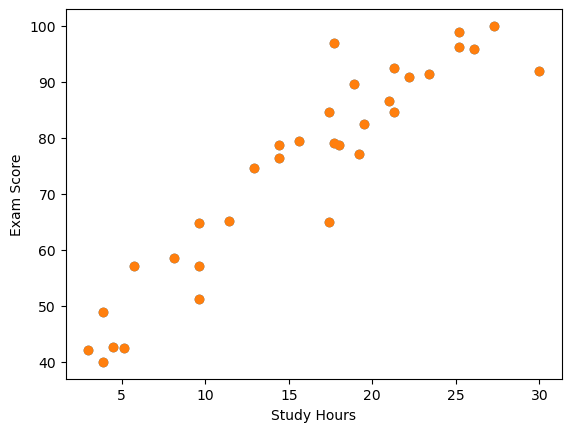

In [6]:
plt.scatter(df['Study Hours'],df['Exam Score'] )
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()


In [9]:
#independent and dependent features
X=df[['Study Hours']]
y=df['Exam Score']

In [10]:
type(X)

pandas.core.frame.DataFrame

In [11]:
type(y)

pandas.core.series.Series

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20, random_state=15)

In [14]:
y_train

18     64.9
1      57.1
2      42.7
32     89.6
6      77.1
3      65.1
29     82.4
26     64.8
9      84.6
4      78.7
28     79.1
10     92.4
27     79.5
13    100.0
17     74.7
15     97.0
22     76.5
31     96.2
11     95.9
7      90.8
0      40.0
23     42.2
5      78.8
12     92.0
21     58.5
8      99.0
Name: Exam Score, dtype: float64

In [15]:
X_train

,Study Hours
18,17.4
1,9.6
2,4.5
32,18.9
6,19.2
3,11.4
29,19.5
26,9.6
9,17.4
4,14.4


In [16]:
y_test

25    42.4
14    86.6
30    91.5
16    57.2
24    51.2
20    49.0
19    84.7
Name: Exam Score, dtype: float64

In [19]:
from sklearn.preprocessing import StandardScaler

In [20]:
scaler=StandardScaler()

In [21]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

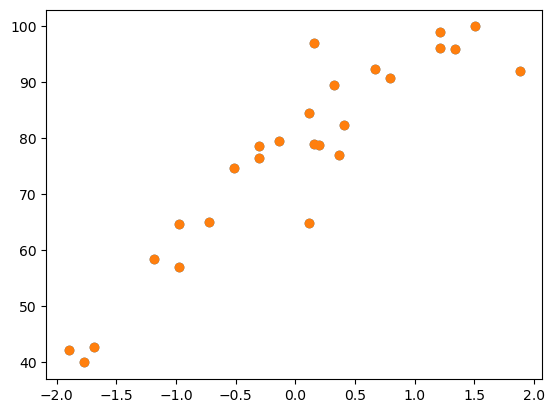

In [23]:
plt.scatter(X_train,y_train)
plt.show()

In [24]:
from sklearn.linear_model import LinearRegression

In [27]:
regression=LinearRegression()

In [28]:
regression.fit(X_train,y_train)

LinearRegression()

In [29]:
print("Coefficient:", regression.coef_)
print("Intercept:" , regression.intercept_)

Coefficient: [16.17860223]
Intercept: 76.9076923076923


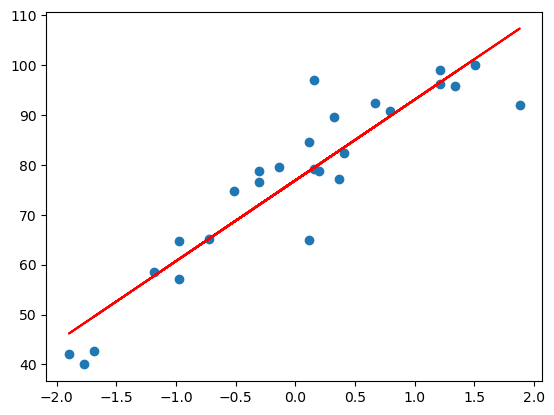

In [30]:
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train),"r")
plt.show()

In [31]:
# y=76.91 +16.18 x

In [32]:
#prediction with test data


In [33]:
y_pred_test=regression.predict(X_test)

In [34]:
y_test

25    42.4
14    86.6
30    91.5
16    57.2
24    51.2
20    49.0
19    84.7
Name: Exam Score, dtype: float64

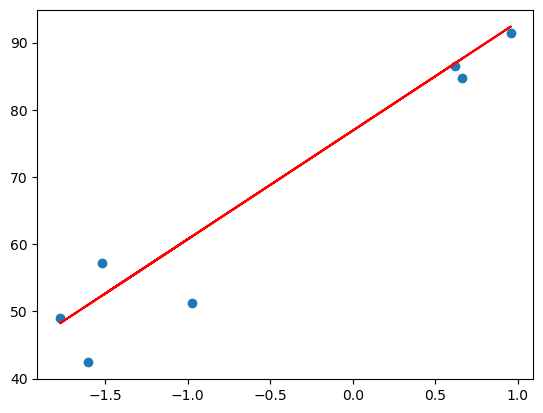

In [35]:
plt.scatter(X_test,y_test)
plt.plot(X_test,regression.predict(X_test),"r")
plt.show()

In [36]:
# performance metrics 
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [37]:
mse=mean_squared_error(y_test,y_pred_test)
mae=mean_absolute_error(y_test,y_pred_test)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

29.458390488333936
4.054868128856141
5.427558427906045


In [38]:
from sklearn.metrics import r2_score
score=r2_score(y_test,y_pred_test)


In [39]:
score

0.9196596206825491

In [40]:
#adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.903591544819059

In [41]:
#new data
scaler.transform([[20]])


C:\Users\silay\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[0.48200796]])

In [42]:
regression.predict(scaler.transform([[5]]))

C:\Users\silay\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([50.72485871])

In [43]:
regression.predict(scaler.transform([[1]]))

C:\Users\silay\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([41.66324575])

In [44]:
regression.predict(scaler.transform([[25]]))

C:\Users\silay\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([96.0329235])